<a href="https://colab.research.google.com/github/oumodavid1625/Work-on-Data-Science/blob/main/HANCOCK_CD8_Analysis_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **HANCOCK CD8 survival analysis**

This notebook evaluates the association of the center-to-front CD8 ratio and combined two-compartment CD8 score with overall survival. It replaces the exploratory notebook with one sequential pipeline, explicit validation, and generated results.

**Run:** In a fresh Colab CPU runtime, select **Runtime → Run all** and upload `StructuredData.zip` and `TMA_CellDensityMeasurements.zip` when prompted. No Google Drive mount is needed. `TMA_Maps.zip` is optional and not used: the measurements already contain patient identifiers. This copy has no saved execution counts or outputs. The setup installs lifelines only and does not replace NumPy, pandas, SciPy, matplotlib or IPython. The final cell offers a ZIP of tables, figures, fitted-model summaries, audit records and run metadata.

Publication numbering is fixed: Tables 1–2, Tables S1–S5 and Figures 2–4 are displayed and exported with the same labels for manuscript transfer. Figures 1 and S1 are external and are not generated. The ZIP contains a Publication_Output_Index.csv and a formatted HTML source for tables and captions.


## 1. Analysis decisions

- Primary endpoint: overall survival (OS), with `deceased` mapped to 1 and `living` to 0. `days_to_last_information` is the supplied observation time; for deceased patients it is used as death time.
- Primary ratio contrast: highest empirical tertile versus the lower two tertiles. Tertiles are calculated on the raw ratio **before** winsorization; actual boundaries and inclusion rules are exported. Continuous log-ratio and 1st/99th percentile winsorization are sensitivity analyses. A log transformation changes the exposure scale; it does not require the exposure itself to be normally distributed.
- Combined score: mean center density + mean front density, scaled per 100 units; this is **not** a pooled tissue density. Its continuous association is exploratory. The joint model contains both markers. Different coefficient p-values do not demonstrate one marker's superiority.
- Clinical adjustment: age, pT1–2 versus pT3–4, p16 negative/positive/not tested, and pN0/pN1–3/unknown. Negative p16 and pN0 are references. Unknown nodal status and untested p16 are separate categories in the main post-review model. Known-status analyses and the previous p16 coding are sensitivity analyses.
- Secondary endpoint retained: **locoregional recurrence-or-death-free survival (LRRDFS)**, defined using the recorded `recurrence` field and death.
- DSS: cause-specific Cox models use the explicit `deceased tumor specific` category; non-tumor deaths are censored at death. Deaths without an assigned cause are excluded in the principal DSS analysis, with extreme-case sensitivity analyses. These are cause-specific hazard estimates, not cumulative-incidence estimates.
- All secondary, subgroup, sensitivity and interaction analyses are exploratory, with nominal two-sided p-values and no multiplicity adjustment. No external validation is performed. PH diagnostics and nonlinear exposure checks are reported; pooled subsite interactions allow separate baseline hazards by subsite and estimate the p16 contrast within tested oropharyngeal patients only; a failed model is logged, never silently simplified.

Sources supplied with this analysis: HANCOCK DOI https://doi.org/10.7937/RCTY-5H16 ; source dictionary https://hancock.research.fau.eu/terminology. The source dictionary was not retrievable during this rebuild. The clinical definitions above disclose the resulting limitations.

In [ ]:
# Keep Colab's existing scientific packages and IPython unchanged.
# Install only the survival-analysis dependency when needed.
import importlib.metadata as metadata
import subprocess
import sys
PACKAGES = ("numpy", "pandas", "scipy", "matplotlib", "lifelines", "ipython")
try:
    lifelines_version = metadata.version("lifelines")
except metadata.PackageNotFoundError:
    lifelines_version = None
if lifelines_version != "0.30.3":
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--quiet", "lifelines==0.30.3"
    ])
print("Dependency setup complete. Python:", sys.version.split()[0])


Dependency setup complete. Python: 3.13.16


In [ ]:
from pathlib import Path
import hashlib
import io
import json
import platform
import re
import warnings
import zipfile
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import scipy
from scipy.stats import wilcoxon, chi2, norm
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
from IPython.utils.capture import capture_output
from lifelines import CoxPHFitter, CoxTimeVaryingFitter, KaplanMeierFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test, proportional_hazard_test
from lifelines.plotting import add_at_risk_counts
from lifelines.exceptions import ConvergenceError, ConvergenceWarning

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
# Change only these paths if running locally. Colab uploads to INPUT_DIR.
INPUT_DIR = Path("/content/hancock_inputs") if IN_COLAB else Path("upload")
OUTPUT_DIR = Path("/content/hancock_results") if IN_COLAB else Path("work/hancock_results_v24")
INPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
# Avoid mixing outputs from earlier runs. Only files listed in this notebook's previous manifest are removed.
manifest_path = OUTPUT_DIR / "output_manifest.json"
if manifest_path.exists():
    for name in json.loads(manifest_path.read_text()):
        target = OUTPUT_DIR / Path(name).name
        if target.is_file():
            target.unlink()
plt.rcParams.update({"font.size": 11, "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "savefig.dpi": 300})
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
model_rows, diagnostic_rows, failure_rows, fit_warning_rows = [], [], [], []
models = {}
written = []
def save_table(frame, name):
    path = OUTPUT_DIR / f"{name}.csv"
    frame.to_csv(path, index=False)
    written.append(path.name)
    return frame

def save_json(value, name):
    path = OUTPUT_DIR / f"{name}.json"
    path.write_text(json.dumps(value, indent=2, default=str))
    written.append(path.name)

print("Output directory:", OUTPUT_DIR)

Output directory: /content/hancock_results


## 2. Load the original archives and validate their contents
Only the two named patient-level JSON files and the CD8 measurement CSV are read. Blood tests and TMA maps are not needed. Files are read directly from ZIPs without extracting arbitrary paths. File hashes identify the exact dataset bytes; hashes are recorded.

In [ ]:
required_archives = ["StructuredData.zip", "TMA_CellDensityMeasurements.zip"]
if IN_COLAB and any(not (INPUT_DIR / name).exists() for name in required_archives):
    from google.colab import files
    print("Upload StructuredData.zip and TMA_CellDensityMeasurements.zip together.")
    uploaded = files.upload()
    for name, content in uploaded.items():
        if Path(name).name in required_archives:
            (INPUT_DIR / Path(name).name).write_bytes(content)
for name in required_archives:
    path = INPUT_DIR / name
    if not path.is_file() or not zipfile.is_zipfile(path):
        raise FileNotFoundError(f"Required valid ZIP is missing: {path}")

def read_member(archive, basename, kind):
    with zipfile.ZipFile(INPUT_DIR / archive) as z:
        names = [name for name in z.namelist() if Path(name).name == basename]
        if len(names) != 1:
            raise ValueError(f"Expected exactly one {basename} in {archive}; found {names}")
        raw = z.read(names[0])
    return pd.DataFrame(json.loads(raw)) if kind == "json" else pd.read_csv(io.BytesIO(raw))

clinical = read_member("StructuredData.zip", "clinical_data.json", "json")
pathology = read_member("StructuredData.zip", "pathological_data.json", "json")
density = read_member("TMA_CellDensityMeasurements.zip", "TMA_celldensity_measurements.csv", "csv")
required_clinical = {"patient_id", "age_at_initial_diagnosis", "survival_status",
    "survival_status_with_cause", "days_to_last_information", "recurrence", "days_to_recurrence"}
required_pathology = {"patient_id", "pN_stage", "pT_stage", "hpv_association_p16", "primary_tumor_site"}
required_density = {"Image", "Case ID", "Missing", "Num Positive per mm^2"}
for label, frame, required in [("clinical", clinical, required_clinical),
    ("pathology", pathology, required_pathology), ("density", density, required_density)]:
    if required - set(frame):
        raise ValueError(f"{label}: missing columns {required - set(frame)}")
for label, frame in [("clinical", clinical), ("pathology", pathology)]:
    frame["patient_id"] = pd.to_numeric(frame["patient_id"], errors="raise").astype("int64")
    if frame.patient_id.isna().any() or frame.patient_id.duplicated().any():
        raise ValueError(f"{label}: patient identifiers must be unique and complete")
if set(clinical.patient_id) != set(pathology.patient_id):
    raise ValueError("Clinical and pathological patient sets differ; resolve before analysis.")
for column, allowed in [("survival_status", {"living", "deceased"}),
    ("recurrence", {"yes", "no"}),
    ("survival_status_with_cause", {"living", "deceased tumor specific", "deceased not tumor specific", "deceased"})]:
    unexpected = set(clinical[column].dropna()) - allowed
    if unexpected:
        raise ValueError(f"Unexpected {column} values: {unexpected}")
if not set(density["Missing"].dropna()).issubset({True, False}):
    raise ValueError("The Missing core flag must be boolean.")
input_hashes = {name: hashlib.sha256((INPUT_DIR/name).read_bytes()).hexdigest()
                for name in required_archives}
print("Loaded:", len(clinical), "clinical patients;", len(pathology),
      "pathology patients;", len(density), "TMA rows")

Upload StructuredData.zip and TMA_CellDensityMeasurements.zip together.


Saving StructuredData.zip to StructuredData.zip
Saving TMA_CellDensityMeasurements.zip to TMA_CellDensityMeasurements.zip
Loaded: 763 clinical patients; 763 pathology patients; 6332 TMA rows


## 3. Core quality control and sequential patient flow
A valid core has an identifiable CD8 compartment, a patient identifier, `Missing=False`, and a finite nonnegative density. Means use valid cores only. Patients require both compartment means and a positive front mean. The main score-versus-ratio comparison uses this common cohort. Patients excluded because of a zero front mean could still be eligible for a separate score-only analysis; this notebook reports that exclusion explicitly.

In [ ]:
cd8 = density.loc[density.Image.astype(str).str.contains(r"(?:^|_)CD8(?:_|\.)", regex=True)].copy()
cd8["compartment"] = cd8.Image.astype(str).map(
    lambda x: "Center" if "TumorCenter" in x else ("Front" if "InvasionFront" in x else None))
cd8["patient_id"] = pd.to_numeric(cd8["Case ID"], errors="coerce")
cd8["density"] = pd.to_numeric(cd8["Num Positive per mm^2"], errors="coerce")
cd8["valid_core"] = (cd8["Missing"].eq(False) & cd8.compartment.notna()
    & cd8.patient_id.notna() & np.isfinite(cd8.density) & cd8.density.ge(0))
unknown_ids = set(cd8.loc[cd8.valid_core, "patient_id"]) - set(clinical.patient_id)
if unknown_ids:
    raise ValueError(f"TMA identifiers absent from clinical data: {unknown_ids}")
save_table(cd8[["Image", "Name", "patient_id", "compartment", "Missing", "density", "valid_core"]], "audit_core_qc")
means = cd8.loc[cd8.valid_core].groupby(["patient_id", "compartment"]).density.agg(["mean", "count"])
wide = means.unstack("compartment")
wide.columns = [f"{comp}_{stat}" for stat, comp in wide.columns]
data = clinical.merge(pathology, on="patient_id", how="inner", validate="one_to_one").merge(
    wide, left_on="patient_id", right_index=True, how="left", validate="one_to_one")
flow, exclusions = [], []
flow.append({"step": "Source clinical and pathology cohort", "excluded": 0, "remaining": len(data)})
def exclude(frame, mask, reason):
    mask = mask.fillna(True)
    exclusions.extend({"patient_id": int(pid), "reason": reason} for pid in frame.loc[mask, "patient_id"])
    result = frame.loc[~mask].copy()
    flow.append({"step": reason, "excluded": int(mask.sum()), "remaining": len(result)})
    return result

data = exclude(data, data.Center_mean.isna(), "No valid center CD8 mean")
data = exclude(data, data.Front_mean.isna(), "No valid front CD8 mean after center filter")
data = exclude(data, data.Front_mean.le(0), "Nonpositive front mean")
data = exclude(data, data.survival_status.isna(), "Missing vital status")
data["OS_days"] = pd.to_numeric(data.days_to_last_information, errors="coerce")
data = exclude(data, ~np.isfinite(data.OS_days), "Missing or nonfinite survival time")
data = exclude(data, data.OS_days.le(0), "Nonpositive survival time")
data["OS_event"] = data.survival_status.map({"living": 0, "deceased": 1}).astype(int)
data["OS_months"] = data.OS_days / 30.44
if not (data.survival_status.eq("living") == data.survival_status_with_cause.eq("living")).all():
    raise ValueError("Vital status and cause-of-death status are inconsistent.")
save_table(pd.DataFrame(flow), "patient_flow")
save_table(pd.DataFrame(exclusions, columns=["patient_id", "reason"]), "patient_exclusions")
display(pd.DataFrame(flow))
print("Analytic patients:", len(data), "; deaths:", data.OS_event.sum())

,step,excluded,remaining
0,Source clinical and pathology cohort,0,763
1,No valid center CD8 mean,49,714
2,No valid front CD8 mean after center filter,5,709
3,Nonpositive front mean,0,709
4,Missing vital status,0,709
5,Missing or nonfinite survival time,0,709
6,Nonpositive survival time,0,709


Analytic patients: 709 ; deaths: 193


## 4. Define exposures and clinical covariates
The reference tertile boundaries are computed from the current analytic cohort; exact numbers are never embedded in labels or model outputs. Unknown categories are mapped explicitly, and unfamiliar stage labels stop the run.

In [ ]:
data["ratio"] = data.Center_mean / data.Front_mean
if data.ratio.le(0).any():
    raise ValueError("Zero center density prevents log-ratio sensitivity analysis; specify a justified policy before proceeding.")
data["ratio_log"] = np.log(data.ratio)
low_w, high_w = data.ratio.quantile([0.01, 0.99])
data["ratio_log_winsor"] = np.log(data.ratio.clip(low_w, high_w))
data["ratio_tertile"], ratio_edges = pd.qcut(data.ratio, 3, labels=["Low", "Medium", "High"], retbins=True)
data["ratio_high"] = data.ratio_tertile.eq("High").astype(int)
data["combined_score"] = data.Center_mean + data.Front_mean
data["score_per100"] = data.combined_score / 100
data["score_tertile"], score_edges = pd.qcut(data.combined_score, 3, labels=["Low", "Medium", "High"], retbins=True)
data["age"] = pd.to_numeric(data.age_at_initial_diagnosis, errors="raise")
node0 = {"pN0"}
node1 = {"pN1", "pN1a", "pN1b", "pN1mi", "pN2", "pN2a", "pN2b", "pN2c", "pN3", "pN3a", "pN3b"}
unknown_node = {"NX", "pNX", "pNx", "Nx"}
unexpected = set(data.pN_stage.dropna()) - node0 - node1 - unknown_node
if unexpected:
    raise ValueError(f"Unmapped pN stages: {unexpected}")
data["node_category"] = np.select([data.pN_stage.isin(node0), data.pN_stage.isin(node1)], ["Negative", "Positive"], default="Unknown")
data["node_positive"] = data.node_category.eq("Positive").astype(int)
data["node_unknown"] = data.node_category.eq("Unknown").astype(int)
early = {"pT1", "pT1a", "pT1b", "pT2"}
advanced = {"pT3", "pT4", "pT4a", "pT4b"}
unclassified = {"TX", "pTX", "pTx", "Tx", "pTis"}
if set(data.pT_stage.dropna()) - early - advanced - unclassified:
    raise ValueError("Unmapped pT stage")
data["pT34"] = data.pT_stage.map({**dict.fromkeys(early, 0), **dict.fromkeys(advanced, 1)})
if not set(data.hpv_association_p16.dropna()).issubset({"negative", "positive", "not_tested"}):
    raise ValueError("Unmapped p16 category")
data["p16_category"] = data.hpv_association_p16.fillna("not_tested")
data["p16_positive"] = data.p16_category.eq("positive").astype(int)
data["p16_untested"] = data.p16_category.eq("not_tested").astype(int)
BASE = ["age", "p16_positive", "p16_untested", "node_positive", "node_unknown", "pT34"]
thresholds = {"ratio_edges": ratio_edges.tolist(), "score_edges": score_edges.tolist(),
    "inclusion": "Low: min <= x <= edge1; Medium: edge1 < x <= edge2; High: edge2 < x <= max",
    "ratio_winsor_limits": [float(low_w), float(high_w)], "tertiles_before_winsorization": True}
save_json(thresholds, "category_definitions")
save_table(data, "analysis_dataset")
for column in ["pN_stage", "node_category", "pT_stage", "p16_category", "survival_status_with_cause"]:
    counts = data[column].fillna("Missing").value_counts(dropna=False).rename_axis("category").reset_index(name="n")
    counts["percent"] = counts.n / len(data) * 100
    save_table(counts, "distribution_" + column)
    print(column); display(counts)
print("Exact thresholds:"); display(pd.Series(thresholds))

pN_stage


,category,n,percent
0,pN0,196,27.644570
1,NX,146,20.592384
2,pN2b,110,15.514810
3,pN1,105,14.809591
4,pN2c,47,6.629055
5,pN2,33,4.654443
6,pN3b,29,4.090268
7,pN2a,27,3.808181
8,pN3,16,2.256700


node_category


,category,n,percent
0,Positive,367,51.763047
1,Negative,196,27.644570
2,Unknown,146,20.592384


pT_stage


...

,category,n,percent
0,not_tested,401,56.558533
1,negative,177,24.964739
2,positive,131,18.476728


survival_status_with_cause


,category,n,percent
0,living,516,72.778561
1,deceased tumor specific,102,14.386460
2,deceased not tumor specific,83,11.706629
3,deceased,8,1.128350


Exact thresholds:


,0
ratio_edges,"[0.02864881361104753, 0.6783380207595653, 1.40..."
score_edges,"[9.018600000000001, 474.745, 1276.214999999999..."
inclusion,Low: min <= x <= edge1; Medium: edge1 < x <= e...
ratio_winsor_limits,"[0.07869920768325965, 11.419961570441863]"
tertiles_before_winsorization,True


## 5. Descriptive results and paired comparison
Follow-up is estimated with reverse Kaplan–Meier, separately from the raw median observation time. The Wilcoxon signed-rank test uses matched center/front values from the same patient rows.

In [ ]:
paired = data[["Center_mean", "Front_mean"]].dropna()
paired_test = wilcoxon(paired.Center_mean, paired.Front_mean, zero_method="wilcox", alternative="two-sided")
reverse_km = KaplanMeierFitter().fit(data.OS_months, event_observed=1-data.OS_event)
description = pd.DataFrame([
    {"measure": "Analytic patients", "value": len(data)},
    {"measure": "Deaths", "value": int(data.OS_event.sum())},
    {"measure": "Age median years", "value": data.age.median()},
    {"measure": "Center density median", "value": paired.Center_mean.median()},
    {"measure": "Front density median", "value": paired.Front_mean.median()},
    {"measure": "Paired Wilcoxon statistic", "value": paired_test.statistic},
    {"measure": "Paired Wilcoxon p", "value": paired_test.pvalue},
    {"measure": "Raw median observation months", "value": data.OS_months.median()},
    {"measure": "Reverse KM median follow-up months", "value": reverse_km.median_survival_time_},
    {"measure": "Front density below 50", "value": int(data.Front_mean.lt(50).sum())}])
save_table(description, "descriptive_summary")
display(description)
baseline_rows = []
for column in ["sex", "primary_tumor_site", "p16_category", "node_category", "pT_stage", "smoking_status"]:
    for value, count in data[column].fillna("Missing").value_counts().items():
        baseline_rows.append({"variable": column, "category": value, "n": count, "percent": 100*count/len(data)})
save_table(pd.DataFrame(baseline_rows), "table1_categorical_characteristics")

,measure,value
0,Analytic patients,709.000000
1,Deaths,193.000000
2,Age median years,61.000000
3,Center density median,393.900000
4,Front density median,344.135000
5,Paired Wilcoxon statistic,119232.000000
6,Paired Wilcoxon p,0.225275
7,Raw median observation months,41.097240
8,Reverse KM median follow-up months,55.354796
9,Front density below 50,46.000000


,variable,category,n,percent
0,sex,male,564,79.548660
1,sex,female,145,20.451340
2,primary_tumor_site,Oropharynx,309,43.582511
3,primary_tumor_site,Larynx,191,26.939351
4,primary_tumor_site,Oral_Cavity,129,18.194640
5,primary_tumor_site,Hypopharynx,80,11.283498
6,p16_category,not_tested,401,56.558533
7,p16_category,negative,177,24.964739
8,p16_category,positive,131,18.476728
9,node_category,Positive,367,51.763047


## 6. Fit models with complete provenance
Every coefficient is exported with its contrast, exact formula, fitted sample size, event count, confidence interval, log likelihood and concordance. Model-specific exclusions and patient identifiers are exported. Constant covariates are only omitted when mathematically unestimable within a subset, and are recorded. Failed fits and convergence warnings are visible; no reduced adjustment set is tried automatically. Main and joint OS comparisons use the same complete-case population.

In [ ]:
def fit_cox(frame, model_id, markers, base=BASE, time_col="OS_months", event_col="OS_event", ph=False, strata=None):
    columns = list(dict.fromkeys(list(base) + list(markers)))
    strata = [] if strata is None else list(strata)
    subset = frame[["patient_id", time_col, event_col] + columns + strata].copy()
    valid = subset[[time_col, event_col] + columns + strata].notna().all(axis=1)
    valid &= np.isfinite(subset[time_col]) & subset[time_col].gt(0)
    audit = subset[["patient_id"]].copy()
    audit["included"] = valid
    audit["missing_fields"] = subset[[time_col, event_col] + columns].isna().apply(
        lambda row: ";".join(row.index[row]), axis=1)
    save_table(audit, f"sample_{model_id}")
    subset = subset.loc[valid]
    constants = [column for column in columns if subset[column].nunique() < 2]
    if any(column in constants for column in markers):
        failure_rows.append({"model": model_id, "error": "Exposure is constant", "n": len(subset), "events": int(subset[event_col].sum())})
        return None
    columns = [column for column in columns if column not in constants]
    formula = " + ".join(columns)
    try:
        if subset[event_col].sum() == 0:
            raise ValueError("No events in fitted population")
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            fitted = CoxPHFitter().fit(subset[[time_col, event_col]+columns+strata],
                duration_col=time_col, event_col=event_col, formula=formula, strata=strata or None)
        convergence_flag = False
        for warning in caught:
            fit_warning_rows.append({"model": model_id, "warning": str(warning.message), "category": warning.category.__name__})
            convergence_flag |= issubclass(warning.category, ConvergenceWarning)
        summary = fitted.summary.reset_index().rename(columns={"covariate": "term"})
        summary["model"] = model_id
        summary["n"] = len(subset)
        summary["events"] = int(subset[event_col].sum())
        summary["formula"] = formula
        summary["strata"] = ";".join(strata)
        summary["omitted_constant_covariates"] = ";".join(constants)
        summary["convergence_warning"] = convergence_flag
        summary["log_likelihood"] = fitted.log_likelihood_
        summary["concordance_apparent"] = fitted.concordance_index_
        summary["event_column"] = event_col
        summary["time_column"] = time_col
        model_rows.extend(summary.to_dict("records"))
        fitted._analysis_convergence_warning = convergence_flag
        models[model_id] = (fitted, subset, columns)
        if ph:
            for transform in ["km", "rank"]:
                diagnostics = proportional_hazard_test(fitted, subset[[time_col,event_col]+columns+strata], time_transform=transform).summary.reset_index().rename(columns={"index":"term"})
                diagnostics["time_transform"] = transform
                diagnostics["model"] = model_id
                diagnostic_rows.extend(diagnostics.to_dict("records"))
        return fitted
    except (ConvergenceError, ValueError, np.linalg.LinAlgError) as exc:
        failure_rows.append({"model": model_id, "error": str(exc), "formula": formula,
            "n": len(subset), "events": int(subset[event_col].sum())})
        print(f"MODEL FAILED [{model_id}]: {exc}")
        return None

common = data.dropna(subset=BASE+["ratio_high", "score_per100"])
for model_id, markers in [("OS_clinical", []), ("OS_ratio", ["ratio_high"]),
    ("OS_score", ["score_per100"]), ("OS_joint", ["ratio_high", "score_per100"])]:
    fit_cox(common, model_id, markers, ph=True)
if any(name not in models for name in ["OS_clinical", "OS_ratio", "OS_score", "OS_joint"]):
    raise RuntimeError("A main model failed. Resolve before manuscript reporting.")
main_results = pd.DataFrame(model_rows)
display(main_results.loc[main_results.term.isin(["ratio_high","score_per100"]),
    ["model","term","n","events","exp(coef)","exp(coef) lower 95%","exp(coef) upper 95%","p"]])
# Nested likelihood-ratio test on the SAME fitted patients. This assesses conditional association,
# not validated predictive performance or clinical utility.
lrt_stat = 2*(models["OS_joint"][0].log_likelihood_ - models["OS_score"][0].log_likelihood_)
save_table(pd.DataFrame([{"comparison": "Add ratio to clinical plus score model", "chi2": lrt_stat,
    "df": 1, "p": chi2.sf(lrt_stat,1), "n": len(common), "events": int(common.OS_event.sum())}]), "joint_ratio_likelihood_ratio_test")

,model,term,n,events,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p
12,OS_ratio,ratio_high,706,191,1.143337,0.849659,1.538522,0.376504
19,OS_score,score_per100,706,191,0.982480,0.969815,0.995312,0.007589
26,OS_joint,ratio_high,706,191,1.221075,0.904938,1.647654,0.191368
27,OS_joint,score_per100,706,191,0.981373,0.968545,0.994372,0.005099


,comparison,chi2,df,p,n,events
0,Add ratio to clinical plus score model,1.679375,1,0.195007,706,191


## 7. Sensitivity analyses and exposure functional form
Models retain the relevant CD8 markers. p16-positive coefficients in the main model compare positive with **tested negative**. An alternative historical p16 binary analysis compares positive with negative **or untested** and is named accordingly. Log-ratio and low-front analyses use the same clinical adjustment as the main models. Winsorization limits come from the full analytic cohort.

Quadratic terms are exploratory checks for departure from linearity on the log-hazard scale; they do not prove linearity when non-significant. PH tests use KM and rank transforms, with exact p-values exported and displayed to four decimal places. Inspect plots and clinically meaningful departures as well as p-values; a non-significant test is not proof of PH.

In [ ]:
for label, frame, base in [
    ("p16_tested", data[data.p16_category.isin(["positive","negative"])], [x for x in BASE if x!="p16_untested"]),
    ("p16_positive_vs_negative_or_untested", data, [x for x in BASE if x!="p16_untested"]),
    ("node_known", data[data.node_unknown.eq(0)], [x for x in BASE if x!="node_unknown"]),
    ("front_at_least_50", data[data.Front_mean.ge(50)], BASE)]:
    for marker_name, markers in [("ratio",["ratio_high"]),("score",["score_per100"]),("joint",["ratio_high","score_per100"])]:
        fit_cox(frame, f"OS_{label}_{marker_name}", markers, base=base)
for marker in ["ratio_log", "ratio_log_winsor"]:
    fit_cox(data, f"OS_{marker}", [marker], ph=True)
functional_rows = []
for marker in ["score_per100", "ratio_log"]:
    frame = data.copy()
    # Center before squaring to reduce numerical collinearity.
    frame["marker_centered"] = frame[marker] - frame[marker].median()
    frame["marker_squared"] = frame.marker_centered**2
    linear_id, quad_id = f"linear_check_{marker}", f"quadratic_check_{marker}"
    linear = fit_cox(frame, linear_id, ["marker_centered"])
    quadratic = fit_cox(frame, quad_id, ["marker_centered","marker_squared"])
    if linear is not None and quadratic is not None:
        value = 2*(quadratic.log_likelihood_-linear.log_likelihood_)
        functional_rows.append({"marker": marker,"chi2":value,"df":1,"p":chi2.sf(value,1)})
save_table(pd.DataFrame(functional_rows), "functional_form_checks")
# Display a concise diagnostic table; preserve full routine text in a file.
ph_main = pd.DataFrame(diagnostic_rows)
ph_main["term"] = ph_main.get("term",ph_main.get("covariate"))
ph_table = ph_main[ph_main.model.eq("OS_joint")].pivot(index="term",columns="time_transform",values="p").reset_index()
ph_table["assessment"] = np.where(ph_table[["km","rank"]].min(axis=1)<0.05,
    "Review possible time dependence", "No evidence detected by these tests")
save_table(ph_table,"PH_joint_model_summary")
print("PROPORTIONAL-HAZARDS DIAGNOSTICS: joint OS model")
with pd.option_context("display.float_format",lambda value:f"{value:.4f}"):
    display(ph_table)
print("These are diagnostic p-values, not tests of association with survival. Four-decimal display avoids rounding a borderline diagnostic p-value to 0.05. Multiple tests can flag by chance; inspect residual plots and the time-varying sensitivity below.")
joint_fit, joint_sample, joint_columns = models["OS_joint"]
previous_random_state = np.random.get_state()
np.random.seed(42)  # reproducible bootstrap LOWESS diagnostic curves only
try:
    with capture_output() as routine_capture:
        joint_fit.check_assumptions(joint_sample[["OS_months","OS_event"]+joint_columns],
            p_value_threshold=0.05,show_plots=True)
finally:
    np.random.set_state(previous_random_state)
diagnostic_details = routine_capture.stdout + routine_capture.stderr
for rich_output in routine_capture.outputs:
    diagnostic_details += "\n" + str(rich_output.data.get("text/plain", ""))
(OUTPUT_DIR/"PH_diagnostic_details.txt").write_text(diagnostic_details)
written.append("PH_diagnostic_details.txt")
for index, number in enumerate(plt.get_fignums()):
    figure = plt.figure(number)
    name = f"ph_diagnostic_{index+1}.png"
    figure.savefig(OUTPUT_DIR/name,bbox_inches="tight")
    written.append(name)
plt.close("all")
print("Residual plots saved. Bootstrap progress and the full library advice are retained in PH_diagnostic_details.txt.")


PROPORTIONAL-HAZARDS DIAGNOSTICS: joint OS model


time_transform,term,km,rank,assessment
0,age,0.4234,0.1791,No evidence detected by these tests
1,node_positive,0.3008,0.2454,No evidence detected by these tests
2,node_unknown,0.2634,0.1935,No evidence detected by these tests
3,p16_positive,0.5286,0.9427,No evidence detected by these tests
4,p16_untested,0.1190,0.2511,No evidence detected by these tests
5,pT34,0.7654,0.6050,No evidence detected by these tests
6,ratio_high,0.6701,0.6662,No evidence detected by these tests
7,score_per100,0.0323,0.0534,Review possible time dependence


These are diagnostic p-values, not tests of association with survival. Four-decimal display avoids rounding a borderline diagnostic p-value to 0.05. Multiple tests can flag by chance; inspect residual plots and the time-varying sensitivity below.
Residual plots saved. Bootstrap progress and the full library advice are retained in PH_diagnostic_details.txt.


### Time-varying effect sensitivity
The PH diagnostics indicate possible time dependence for the combined score. An exploratory piecewise Cox model estimates score and age effects before and after **36 months**, chosen as a fixed three-year horizon for this post-review sensitivity, not optimized from the observed results. Patients are split at that horizon using counting-process intervals. Do not interpret the ordinary Cox coefficient as an effect proven constant over time. This sensitivity is not a substitute for external validation.

In [ ]:
SPLIT_MONTHS = 36.0
interval_rows = []
for _, row in common.iterrows():
    values = {column: float(row[column]) for column in BASE+["ratio_high","score_per100"]}
    first = {"patient_id":int(row.patient_id),"start":0.0,"stop":min(row.OS_months,SPLIT_MONTHS),
        "event":int(row.OS_event and row.OS_months<=SPLIT_MONTHS), **values,
        "score_late":0.0,"age_late":0.0}
    interval_rows.append(first)
    if row.OS_months > SPLIT_MONTHS:
        interval_rows.append({"patient_id":int(row.patient_id),"start":SPLIT_MONTHS,"stop":float(row.OS_months),
            "event":int(row.OS_event),**values,"score_late":float(row.score_per100),"age_late":float(row.age)})
intervals = pd.DataFrame(interval_rows)
assert intervals.event.sum() == common.OS_event.sum()
tv = CoxTimeVaryingFitter()
# No automatic penalties or removal of terms on failure.
try:
    tv.fit(intervals,id_col="patient_id",start_col="start",stop_col="stop",event_col="event",
        formula=" + ".join(BASE+["ratio_high","score_per100","score_late","age_late"]))
    save_table(tv.summary.reset_index(),"time_varying_model_coefficients")
    period_rows = []
    for marker, interaction in [("score_per100","score_late"),("age","age_late")]:
        for period in ["0 to 36 months", "After 36 months"]:
            terms = [marker] if period=="0 to 36 months" else [marker,interaction]
            coefficient = tv.params_.loc[terms].sum()
            positions = [tv.params_.index.get_loc(term) for term in terms]
            covariance = tv.variance_matrix_.to_numpy()
            variance = covariance[np.ix_(positions,positions)].sum()
            se = np.sqrt(variance)
            period_rows.append({"marker":marker,"period":period,"HR":np.exp(coefficient),
                "lower_95":np.exp(coefficient-1.96*se),"upper_95":np.exp(coefficient+1.96*se),
                "n_patients":len(common),"total_events":int(common.OS_event.sum()),
                "patients_entering_period":int(len(common) if period=="0 to 36 months" else common.OS_months.gt(SPLIT_MONTHS).sum()),
                "deaths_in_period":int((common.OS_event.eq(1)&(common.OS_months.le(SPLIT_MONTHS) if period=="0 to 36 months" else common.OS_months.gt(SPLIT_MONTHS))).sum())})
    save_table(pd.DataFrame(period_rows),"time_varying_period_estimates")
    interaction_table = tv.summary.loc[["score_late","age_late"],["coef","se(coef)","p"]].reset_index()
    interaction_table["meaning"] = ["Score effect: after vs before 36 months", "Age effect: after vs before 36 months"]
    save_table(interaction_table,"time_varying_interaction_tests")
    print("EXPLORATORY PERIOD-SPECIFIC HAZARD RATIOS")
    display(pd.DataFrame(period_rows))
    print("FORMAL TESTS OF CHANGE IN EFFECT BETWEEN PERIODS")
    display(interaction_table)
    print("The 36-month split was a post-review sensitivity choice. Different significance within periods alone does not establish a time interaction.")
except (ConvergenceError,ValueError,np.linalg.LinAlgError) as exc:
    failure_rows.append({"model":"time_varying_joint", "error":str(exc),"n":len(common),"events":int(common.OS_event.sum())})
    print("Time-varying model failed; no substitute fitted:",exc)

EXPLORATORY PERIOD-SPECIFIC HAZARD RATIOS


,marker,period,HR,lower_95,upper_95,n_patients,total_events,patients_entering_period,deaths_in_period
0,score_per100,0 to 36 months,0.994439,0.980669,1.008403,706,191,706,123
1,score_per100,After 36 months,0.947874,0.919131,0.977516,706,191,388,68
2,age,0 to 36 months,1.035406,1.015768,1.055423,706,191,706,123
3,age,After 36 months,1.039719,1.012606,1.067558,706,191,388,68


FORMAL TESTS OF CHANGE IN EFFECT BETWEEN PERIODS


,covariate,coef,se(coef),p,meaning
0,score_late,-0.047957,0.016860,0.004450,Score effect: after vs before 36 months
1,age_late,0.004157,0.016449,0.800491,Age effect: after vs before 36 months


The 36-month split was a post-review sensitivity choice. Different significance within periods alone does not establish a time interaction.


## 8. Secondary endpoints and metastasis audit
LRRDFS counts the first recorded locoregional recurrence or all-cause death, at the earlier time. DSS uses OS observation time with cause-specific event coding. All secondary endpoint definitions and exclusions are exported. Unknown-cause DSS deaths are not quietly treated as known non-tumor deaths. The extreme-case analyses show the consequence of assigning all eight unknown deaths either way.



In [ ]:
rec_time = pd.to_numeric(data.days_to_recurrence, errors="coerce")
rec_event = data.recurrence.eq("yes")
invalid_rec = rec_event & (~np.isfinite(rec_time) | rec_time.lt(0) | rec_time.gt(data.OS_days))
inconsistent_rec = ~rec_event & rec_time.notna()
if invalid_rec.any() or inconsistent_rec.any():
    raise ValueError("Recurrence flags and times are inconsistent; adjudicate before secondary analysis.")
data["LRRDFS_event"] = (rec_event | data.OS_event.eq(1)).astype(int)
data["LRRDFS_months"] = np.minimum(data.OS_days,
    rec_time.where(rec_event, np.inf)) / 30.44
# Full-cohort composite sanity check before endpoint-specific time exclusions.
assert data.LRRDFS_event.sum() >= data.OS_event.sum()
data["DSS_event"] = data.survival_status_with_cause.eq("deceased tumor specific").astype(int)
data["DSS_months"] = data.OS_months
unknown_cause = data.OS_event.eq(1) & data.survival_status_with_cause.eq("deceased")
secondary_definitions = []
for name, frame, t, e, description in [
    ("LRRDFS", data, "LRRDFS_months", "LRRDFS_event", "First recorded locoregional recurrence or all-cause death"),
    ("DSS_known_cause", data[~unknown_cause], "DSS_months", "DSS_event", "Tumor-specific death; unspecified-cause deaths excluded"),
    ("DSS_unknown_as_nontumor", data, "DSS_months", "DSS_event", "Sensitivity: unspecified deaths censored at death")]:
    secondary_definitions.append({"endpoint":name,"definition":description,"eligible_n":len(frame),
        "events_before_model_exclusions":int(frame[e].sum())})
    for marker_name, markers in [("ratio",["ratio_high"]),("score",["score_per100"]),("joint",["ratio_high","score_per100"])]:
        fit_cox(frame, f"{name}_{marker_name}", markers, time_col=t, event_col=e, ph=True)
worst = data.copy()
worst["DSS_unknown_event"] = (worst.DSS_event.eq(1) | unknown_cause).astype(int)
secondary_definitions.append({"endpoint":"DSS_unknown_as_tumor", "definition":"Sensitivity: all unspecified deaths counted as tumor deaths", "eligible_n":len(worst), "events_before_model_exclusions":int(worst.DSS_unknown_event.sum())})
for marker_name, markers in [("ratio",["ratio_high"]),("score",["score_per100"]),("joint",["ratio_high","score_per100"])]:
    fit_cox(worst,f"DSS_unknown_as_tumor_{marker_name}",markers,time_col="DSS_months",event_col="DSS_unknown_event",ph=True)
save_table(pd.DataFrame(secondary_definitions), "secondary_endpoint_definitions")
met_cols = [column for column in data if column.startswith(("metastasis_", "days_to_metastasis_"))]
save_table(data[["patient_id","primarily_metastasis","OS_days","OS_event"]+met_cols], "metastasis_patient_audit")
met_audit = []
for index in range(1,5):
    location, timing = f"metastasis_{index}_locations", f"days_to_metastasis_{index}"
    if location not in data or timing not in data:
        raise ValueError(f"Missing expected metastasis fields for episode {index}")
    days = pd.to_numeric(data[timing],errors="coerce")
    for label, mask in [("location recorded",data[location].notna()), ("time recorded",days.notna()),
        ("location without time",data[location].notna()&days.isna()),
        ("time without location",days.notna()&data[location].isna()),
        ("negative time",days.lt(0)), ("after last observation",days.gt(data.OS_days)),
        ("lymph nodes only",data[location].eq("LymphNodes"))]:
        met_audit.append({"episode":index,"check":label,"n":int(mask.sum())})
save_table(pd.DataFrame(met_audit), "metastasis_field_audit")
save_table(data.primarily_metastasis.fillna("Missing").value_counts().rename_axis("category").reset_index(name="n"), "baseline_metastasis_flag_audit")
display(pd.DataFrame(secondary_definitions))

,endpoint,definition,eligible_n,events_before_model_exclusions
0,LRRDFS,First recorded locoregional recurrence or all-...,709,270
1,DSS_known_cause,Tumor-specific death; unspecified-cause deaths...,701,102
2,DSS_unknown_as_nontumor,Sensitivity: unspecified deaths censored at death,709,102
3,DSS_unknown_as_tumor,Sensitivity: all unspecified deaths counted as...,709,110


## 9. Exploratory subsite analyses with identifiable p16 adjustment

The data show that all tested p16 results occur in oropharyngeal tumors; non-oropharyngeal sites are entirely untested. The one untested oropharyngeal patient is excluded from these subsite analyses. A p16-positive versus tested-negative contrast is estimated **within oropharynx only**. p16 adjustment is not identifiable within the other sites, and is not claimed there.

Subsite-specific models use age, nodal categories, pT stage and the marker; oropharyngeal models additionally use p16 positivity. Formal heterogeneity tests use pooled Cox models **stratified by anatomical subsite**, allowing different baseline hazards. They retain a within-oropharynx p16 contrast and add marker-by-site terms.


In [ ]:
site_crosstab = pd.crosstab(common.primary_tumor_site,common.p16_category).reset_index()
save_table(site_crosstab,"p16_subsite_overlap")
print("p16 TESTING COVERAGE BY SUBSITE: main complete-case population")
display(site_crosstab)
# Explicit design rule: tested results occur in oropharynx in these supplied files.
oro = data.primary_tumor_site.eq("Oropharynx")
if data.loc[~oro,"p16_category"].isin(["positive","negative"]).any():
    raise ValueError("New data contain tested non-oropharyngeal cases: reassess the stated subsite design before proceeding.")
site_eligible = data[~oro | data.p16_category.isin(["positive","negative"])].copy()
subsite_plan=[]
for site in sorted(site_eligible.primary_tumor_site.dropna().unique()):
    frame=site_eligible[site_eligible.primary_tumor_site.eq(site)]
    site_id=re.sub(r"[^a-z0-9]+","_",site.lower()).strip("_")
    base=["age","node_positive","node_unknown","pT34"]
    if site=="Oropharynx":
        base.append("p16_positive")
    for label,markers in [("ratio",["ratio_high"]),("score",["score_per100"])]:
        fitted=fit_cox(frame,f"site_{site_id}_{label}",markers,base=base)
        subsite_plan.append({"site":site,"marker":label,"p16_adjustment":
            "Positive vs tested negative" if site=="Oropharynx" else "Not estimable; all untested",
            "planned_covariates":" + ".join(base),"fit_status":
            "Failed" if fitted is None else ("Unstable" if fitted._analysis_convergence_warning else "Converged")})
save_table(pd.DataFrame(subsite_plan),"subsite_adjustment_plan")
# p16-positive is zero in non-oropharyngeal strata and therefore supplies no
# between-site p16 comparison. Its coefficient is estimated within oropharynx.
site_frame=site_eligible.dropna(subset=BASE+["ratio_high","score_per100"]).copy()
site_names=sorted(site_frame.primary_tumor_site.unique())
pooled_base=["age","node_positive","node_unknown","pT34","p16_positive"]
interaction_results=[]
for marker in ["ratio_high","score_per100"]:
    terms=[]
    for index,site in enumerate(site_names[1:],1):
        term=f"interaction_{marker}_{index}"
        site_frame[term]=site_frame[marker]*site_frame.primary_tumor_site.eq(site).astype(int)
        terms.append(term)
    reduced=fit_cox(site_frame,f"interaction_base_{marker}",[marker],base=pooled_base,strata=["primary_tumor_site"])
    full=fit_cox(site_frame,f"interaction_full_{marker}",[marker]+terms,base=pooled_base,strata=["primary_tumor_site"])
    stable=(reduced is not None and full is not None and not reduced._analysis_convergence_warning and not full._analysis_convergence_warning)
    stat=2*(full.log_likelihood_-reduced.log_likelihood_) if stable else np.nan
    interaction_results.append({"marker":marker,"reference_site":site_names[0],"chi2":stat,
        "df":len(terms),"p":chi2.sf(stat,len(terms)) if stable else np.nan,"n":len(site_frame),
        "events":int(site_frame.OS_event.sum()),"baseline_hazard":"Stratified by subsite",
        "status":"Converged; exploratory test available" if stable else "Withheld; inspect model diagnostics"})
save_table(pd.DataFrame(interaction_results),"subsite_interaction_tests")
print("FORMAL SUBSITE HETEROGENEITY TESTS: stratified baseline hazards")
display(pd.DataFrame(interaction_results))
print("These exploratory tests assess heterogeneity of marker associations; they do not establish predictive or clinical superiority.")


p16 TESTING COVERAGE BY SUBSITE: main complete-case population


p16_category,primary_tumor_site,negative,not_tested,positive
0,Hypopharynx,0,78,0
1,Larynx,0,191,0
2,Oral_Cavity,0,128,0
3,Oropharynx,177,1,131


FORMAL SUBSITE HETEROGENEITY TESTS: stratified baseline hazards


,marker,reference_site,chi2,df,p,n,events,baseline_hazard,status
0,ratio_high,Hypopharynx,1.145748,3,0.766043,705,191,Stratified by subsite,Converged; exploratory test available
1,score_per100,Hypopharynx,1.680211,3,0.641342,705,191,Stratified by subsite,Converged; exploratory test available


These exploratory tests assess heterogeneity of marker associations; they do not establish predictive or clinical superiority.


## 10. Numbered manuscript figures and analysis exports

Figure 2 shows ratio Kaplan–Meier curves; Figure 3 shows combined-score Kaplan–Meier curves; Figure 4 retains the manuscript's **univariable** clinical-factor forest plot. The adjusted joint-model forest is exported separately as an unnumbered diagnostic. Figures 1 and S1 are external and are deliberately not generated. The publication-table section below uses Tables 1–2 and S1–S5, with dedicated CSV and HTML exports and explanatory footnotes.


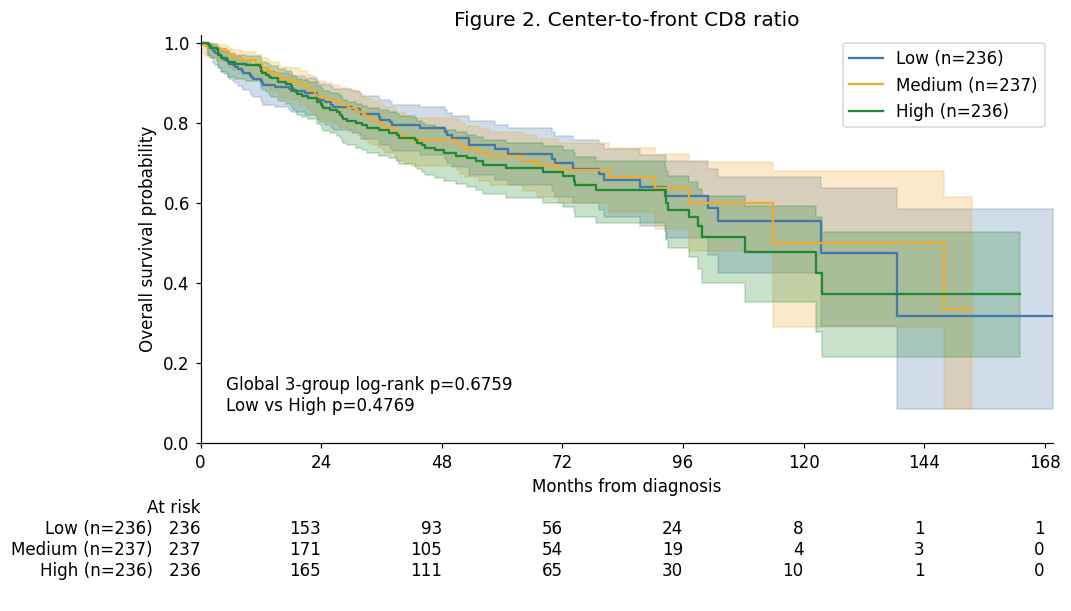

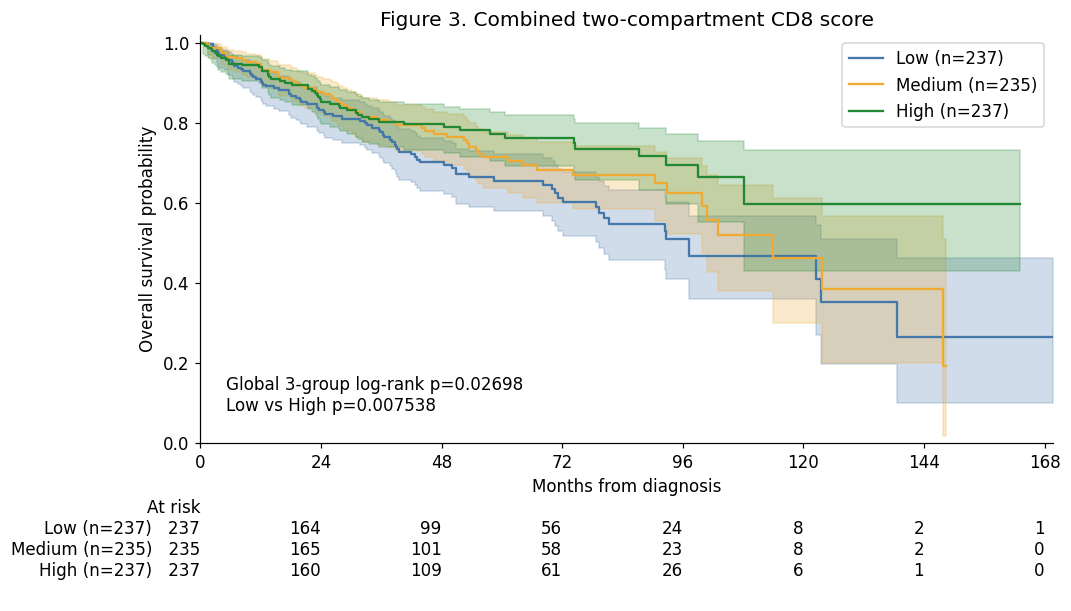

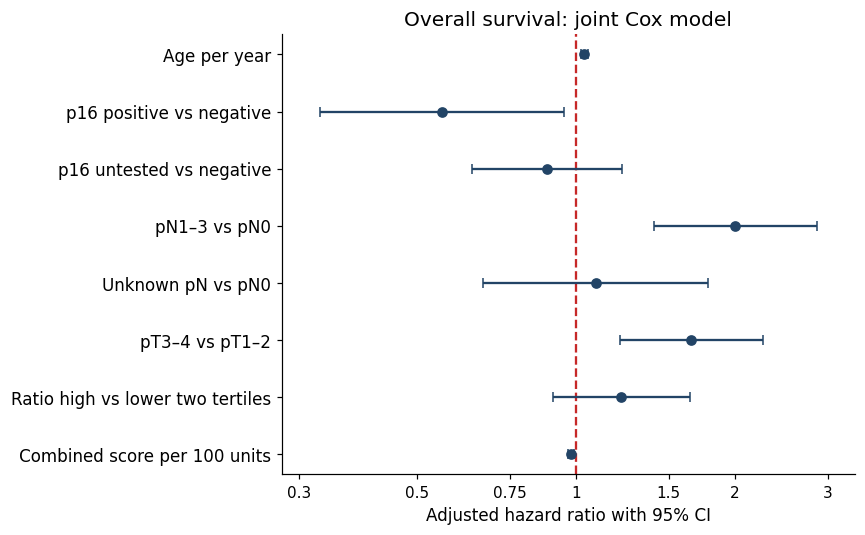

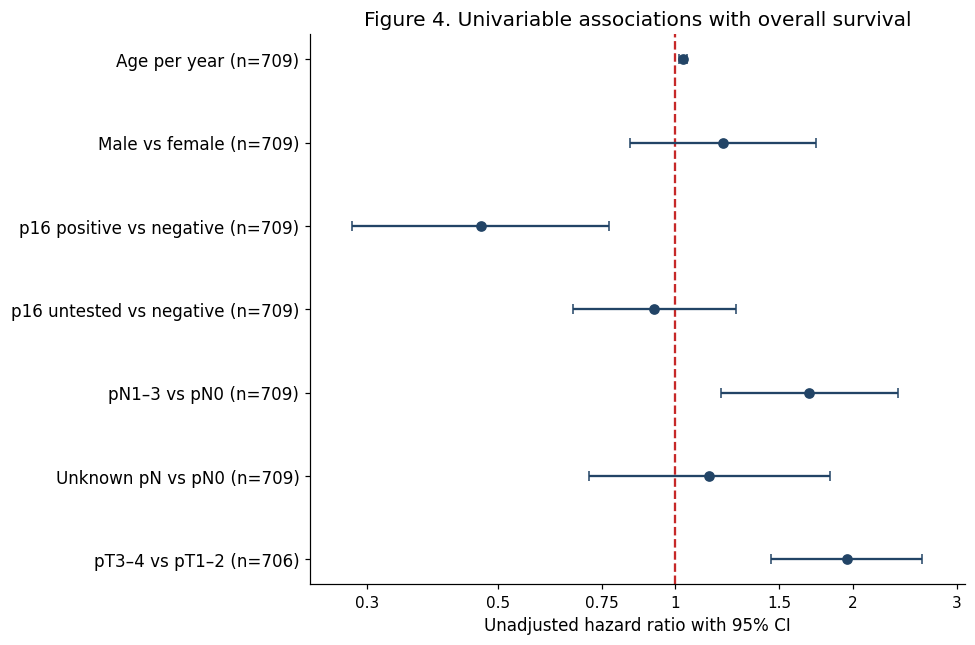

MAIN MODEL FIT STATUS


,model,n,events,convergence
0,OS_clinical,706,191,Converged
1,OS_ratio,706,191,Converged
2,OS_score,706,191,Converged
3,OS_joint,706,191,Converged


Main adjusted CD8 results:


,model,term,n,events,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p
12,OS_ratio,ratio_high,706,191,1.143337,0.849659,1.538522,0.376504
19,OS_score,score_per100,706,191,0.982480,0.969815,0.995312,0.007589
26,OS_joint,ratio_high,706,191,1.221075,0.904938,1.647654,0.191368
27,OS_joint,score_per100,706,191,0.981373,0.968545,0.994372,0.005099


In [ ]:
logrank_rows = []
for column, title, filename in [("ratio_tertile","Figure 2. Center-to-front CD8 ratio","Figure_2_Ratio_Kaplan_Meier"),
    ("score_tertile","Figure 3. Combined two-compartment CD8 score","Figure_3_Combined_CD8_Kaplan_Meier")]:
    fig, ax = plt.subplots(figsize=(10,7))
    fitters = []
    for label, color in zip(["Low","Medium","High"],["#4477AA","#EEAA33","#228833"]):
        frame = data[data[column].eq(label)]
        km = KaplanMeierFitter().fit(frame.OS_months,frame.OS_event,label=f"{label} (n={len(frame)})")
        km.plot_survival_function(ax=ax,ci_show=True,color=color)
        fitters.append(km)
    global_test = multivariate_logrank_test(data.OS_months,data[column],data.OS_event)
    low, high = data[data[column].eq("Low")], data[data[column].eq("High")]
    pairwise = logrank_test(low.OS_months,high.OS_months,low.OS_event,high.OS_event)
    ax.set(title=title,xlabel="Months from diagnosis",ylabel="Overall survival probability",ylim=(0,1.02))
    ax.text(0.03,0.08,f"Global 3-group log-rank p={global_test.p_value:.4g}\nLow vs High p={pairwise.p_value:.4g}",transform=ax.transAxes)
    ax.set_xticks(np.arange(0,169,24))
    ax.set_xlim(0, max(168, data.OS_months.max()))
    add_at_risk_counts(*fitters,ax=ax,rows_to_show=["At risk"],xticks=np.arange(0,169,24))
    fig.subplots_adjust(bottom=0.35)
    fig.savefig(OUTPUT_DIR/f"{filename}.png",bbox_inches="tight")
    written.append(f"{filename}.png")
    fig.savefig(OUTPUT_DIR/f"{filename}.svg",bbox_inches="tight")
    written.append(f"{filename}.svg")
    plt.show(); plt.close(fig)
    logrank_rows.append({"grouping":column,"global_p":global_test.p_value,"low_vs_high_p":pairwise.p_value})
save_table(pd.DataFrame(logrank_rows), "kaplan_meier_logrank_tests")
# Refit each clinical factor separately for the manuscript's univariable Figure 4.
# Multiple dummy coefficients represent a single categorical clinical factor.
data["sex_male"] = data.sex.map({"male":1,"female":0})
univ_models = [("univ_age",["age"]),("univ_sex",["sex_male"]),
    ("univ_p16",["p16_positive","p16_untested"]),
    ("univ_node",["node_positive","node_unknown"]),("univ_pT",["pT34"])]
for model_id,terms in univ_models:
    fit_cox(data,model_id,terms,base=[])
for model_id,term in [("OS_unadjusted_ratio","ratio_high"),("OS_unadjusted_score","score_per100")]:
    fit_cox(data,model_id,[term],base=[])
all_results = pd.DataFrame(model_rows)
def format_forest_axis(ax, ci_lower, ci_upper):
    """Show conventional decimal hazard-ratio ticks on a log scale."""
    from matplotlib.ticker import FixedLocator, NullLocator, FuncFormatter
    lower = max(float(np.min(ci_lower))/1.18, np.finfo(float).tiny)
    upper = float(np.max(ci_upper))*1.18
    lower = min(lower, 1/1.18)
    upper = max(upper, 1.18)
    ax.set_xscale("log")
    ax.set_xlim(lower, upper)
    candidates = sorted({value * 10.0**exponent
        for exponent in range(int(np.floor(np.log10(lower))), int(np.ceil(np.log10(upper)))+1)
        for value in (1, 1.5, 2, 3, 5, 7.5)
        if lower <= value * 10.0**exponent <= upper})
    if len(candidates) > 10:
        candidates = sorted(set(candidates[::2] + ([1.0] if lower <= 1.0 <= upper else [])))
    ax.xaxis.set_major_locator(FixedLocator(candidates))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, pos: f"{value:g}"))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.tick_params(axis="x", labelsize=10)
    ax.axvline(1, color="#C62828", linestyle="--", linewidth=1.5, zorder=1)

forest = all_results[all_results.model.eq("OS_joint")].copy()
labels = {"age":"Age per year", "p16_positive":"p16 positive vs negative", "p16_untested":"p16 untested vs negative",
    "node_positive":"pN1–3 vs pN0", "node_unknown":"Unknown pN vs pN0", "pT34":"pT3–4 vs pT1–2",
    "ratio_high":"Ratio high vs lower two tertiles", "score_per100":"Combined score per 100 units", "sex_male":"Male vs female"}
fig, ax = plt.subplots(figsize=(8,5))
y = np.arange(len(forest))
hr, lo, hi = (forest[x].to_numpy() for x in ["exp(coef)","exp(coef) lower 95%","exp(coef) upper 95%"])
ax.errorbar(hr,y,xerr=[hr-lo,hi-hr],fmt="o",color="#224466",capsize=3)
format_forest_axis(ax, lo, hi)
ax.set_yticks(y,forest.term.map(labels));ax.invert_yaxis()
ax.set(xlabel="Adjusted hazard ratio with 95% CI",title="Overall survival: joint Cox model")
fig.tight_layout();fig.savefig(OUTPUT_DIR/"Diagnostic_Joint_Model_Forest.png",bbox_inches="tight")
written.append("Diagnostic_Joint_Model_Forest.png");plt.show();plt.close(fig)
# Figure 4 is univariable; the multivariable joint forest above is unnumbered.
univ_results=all_results[all_results.model.isin([item[0] for item in univ_models])].copy()
if len(univ_results)!=sum(len(terms) for _,terms in univ_models) or univ_results.convergence_warning.any():
    raise RuntimeError("Figure 4 requires all planned stable univariable fits; inspect model diagnostics.")
save_table(univ_results,"Figure_4_Source_Data")
fig,ax=plt.subplots(figsize=(9,6))
y=np.arange(len(univ_results))
hr,lo,hi=(univ_results[column].to_numpy() for column in ["exp(coef)","exp(coef) lower 95%","exp(coef) upper 95%"])
ax.errorbar(hr,y,xerr=[hr-lo,hi-hr],fmt="o",color="#224466",capsize=3)
format_forest_axis(ax, lo, hi)
axis_labels=[f"{labels[row.term]} (n={int(row.n)})" for _,row in univ_results.iterrows()]
ax.set_yticks(y,axis_labels);ax.invert_yaxis()
ax.set(title="Figure 4. Univariable associations with overall survival",xlabel="Unadjusted hazard ratio with 95% CI")
fig.tight_layout()
for extension in ["png","svg"]:
    name=f"Figure_4_Univariable_Forest.{extension}"
    fig.savefig(OUTPUT_DIR/name,bbox_inches="tight")
    written.append(name)
plt.show();plt.close(fig)
save_table(all_results,"all_model_coefficients")
save_table(all_results[all_results.model.isin(["OS_clinical","OS_ratio","OS_score","OS_joint"])],"table2_main_models")
save_table(all_results[all_results.model.str.startswith("site_")],"table_subsite_models")
save_table(all_results[~all_results.model.str.startswith("OS_") & ~all_results.model.str.startswith(("site_","interaction_","linear_","quadratic_"))],"table_secondary_endpoints")
save_table(pd.DataFrame(diagnostic_rows),"proportional_hazards_tests")
save_table(pd.DataFrame(failure_rows,columns=["model","error","formula","n","events"]),"model_failures")
save_table(pd.DataFrame(fit_warning_rows,columns=["model","warning","category"]),"model_warnings")
diagnostic_status=[]
for name in ["OS_clinical","OS_ratio","OS_score","OS_joint"]:
    fitted,subset,columns=models[name]
    diagnostic_status.append({"model":name,"n":len(subset),"events":int(subset.OS_event.sum()),
        "convergence":"Review" if fitted._analysis_convergence_warning else "Converged"})
save_table(pd.DataFrame(diagnostic_status),"main_model_status")
print("MAIN MODEL FIT STATUS")
display(pd.DataFrame(diagnostic_status))
print("Main adjusted CD8 results:")
display(all_results.loc[all_results.model.isin(["OS_ratio","OS_score","OS_joint"]) & all_results.term.isin(["ratio_high","score_per100"]),
    ["model","term","n","events","exp(coef)","exp(coef) lower 95%","exp(coef) upper 95%","p"]])

## Numbered manuscript tables and figure legends

The following tables will be generated here: **Table 1, Table 2, Tables S1–S5**. Numbered figures are **Figures 2–4**. A single index identifies every export. Figures 1 and S1 remain outside the computational analysis.


In [ ]:
# Figures 1 and S1 are external illustrations and are deliberately not generated.
import html
from IPython.display import HTML

publication_sections = []
publication_index = []
TABLE_TITLES = {
    "Table 1": "Patient characteristics",
    "Table 2": "Multivariable Cox regression for overall survival",
    "Table S1": "Exploratory time-varying associations with overall survival",
    "Table S2": "Associations of CD8 metrics with survival endpoints",
    "Table S3": "Sensitivity analyses for p16 data handling",
    "Table S4": "Sensitivity analyses for the center-to-front CD8 ratio",
    "Table S5": "Subsite-stratified sensitivity analyses",
}
STYLE = """body{font-family:Arial,sans-serif;color:#111;max-width:1500px;margin:36px auto;padding:0 24px;line-height:1.45}
h1,h2,h3{color:#000}table{border-collapse:collapse;width:100%;margin:16px 0;font-size:13px}
th,td{border:1px solid #d9d9d9;padding:9px 12px;text-align:left;vertical-align:middle}
th{background:#e7edf2}tbody tr:nth-child(even){background:#f7f9fb}
p{max-width:1100px}img{max-width:100%;height:auto}section{margin:36px 0;break-inside:avoid}small{font-size:12px}"""

def p_text(value):
    if pd.isna(value):
        return "Not estimable"
    return "<0.001" if value < 0.001 else f"{value:.3f}"

def hr_text(row):
    return f"{row['exp(coef)']:.3f} ({row['exp(coef) lower 95%']:.3f}–{row['exp(coef) upper 95%']:.3f})"

def coefficient(model_id, term):
    found = all_results[(all_results.model == model_id) & (all_results.term == term)]
    if len(found) != 1:
        raise ValueError(f"Expected one fitted result for {model_id}/{term}; found {len(found)}")
    row = found.iloc[0]
    if bool(row.convergence_warning):
        raise ValueError(f"Unstable estimate cannot enter a publication table: {model_id}/{term}")
    return row

def publish_table(label, frame, footnote):
    title = f"{label}. {TABLE_TITLES[label]}"
    stem = label.replace(" ", "_")
    save_table(frame, stem)
    fragment = f"<section><h2>{html.escape(title)}</h2>" + frame.to_html(index=False, escape=True) + f"<p>{html.escape(footnote)}</p></section>"
    page = f"<!doctype html><html><head><meta charset='utf-8'><title>{html.escape(title)}</title><style>{STYLE}</style></head><body>{fragment}</body></html>"
    path = OUTPUT_DIR / f"{stem}.html"
    path.write_text(page)
    written.append(path.name)
    publication_sections.append(fragment)
    publication_index.append({"label":label,"title":TABLE_TITLES[label],"file":path.name,"data_file":f"{stem}.csv","note":footnote})
    display(HTML(fragment))

# Table 1: complete descriptive table. Unclassified pT is not labeled missing.
t1 = []
def characteristic(name, category, value):
    t1.append({"Characteristic":name,"Category or summary":category,"Value":value})

def descriptive(series, digits=1):
    q = series.quantile([0.25,0.5,0.75])
    return f"{q.loc[0.5]:.{digits}f} ({q.loc[0.25]:.{digits}f}–{q.loc[0.75]:.{digits}f})"

characteristic("Patients", "Total", str(len(data)))
characteristic("Age, years", "Median (IQR)", descriptive(data.age))
characteristic("Age, years", "Range", f"{data.age.min():.0f}–{data.age.max():.0f}")
for column,label in [("sex","Sex"),("primary_tumor_site","Primary tumor site"),
    ("smoking_status","Smoking status"),("p16_category","p16 status"),("node_category","Nodal category")]:
    for category,count in data[column].fillna("Missing").value_counts().items():
        display_category = str(category).replace("_"," ")
        characteristic(label,display_category,f"{count} ({100*count/len(data):.1f}%)")
for category,mask in [("pT1–2",data.pT34.eq(0)),("pT3–4",data.pT34.eq(1))]:
    characteristic("pT stage",category,f"{mask.sum()} ({100*mask.mean():.1f}%)")
for category,count in data.loc[data.pT34.isna(),"pT_stage"].fillna("Missing").value_counts().items():
    characteristic("pT stage",str(category)+" (outside modeled categories)",f"{count} ({100*count/len(data):.1f}%)")
characteristic("Deaths", "All causes",f"{data.OS_event.sum()} ({100*data.OS_event.mean():.1f}%)")
characteristic("Follow-up, months", "Reverse Kaplan–Meier median", f"{reverse_km.median_survival_time_:.2f}")
characteristic("Observation time, months", "Raw median (IQR)", descriptive(data.OS_months,2))
characteristic("CD8 center density, cells/mm²", "Median (IQR)", descriptive(data.Center_mean))
characteristic("CD8 front density, cells/mm²", "Median (IQR)", descriptive(data.Front_mean))
characteristic("Combined two-compartment CD8 score", "Median (IQR)", descriptive(data.combined_score))
characteristic("Center-to-front CD8 ratio", "Median (IQR)", descriptive(data.ratio,3))
publish_table("Table 1",pd.DataFrame(t1),"Categorical values are n (%), with the full analytic cohort as denominator. IQR, interquartile range. Reverse Kaplan–Meier follow-up is distinct from raw observation time. The combined score is the sum of compartment means, not a pooled density. TX and pTis are reported separately and excluded from pT1–2 versus pT3–4 adjusted models.")

# Table 2: one row per covariate, four columns matching the manuscript model numbering.
main_model_names = [("OS_clinical","Model 1 Clinical"),("OS_ratio","Model 2 Plus ratio"),
                    ("OS_score","Model 3 Plus score"),("OS_joint","Model 4 Joint")]
main_terms = BASE+["ratio_high","score_per100"]
t2=[]
for term in main_terms:
    item={"Variable or contrast":labels.get(term,term)}
    for model_id,model_label in main_model_names:
        found=all_results[(all_results.model==model_id)&(all_results.term==term)]
        if found.empty:
            item[model_label+" HR (95% CI)"]="—";item[model_label+" p"]="—"
        else:
            row=coefficient(model_id,term)
            item[model_label+" HR (95% CI)"]=hr_text(row);item[model_label+" p"]=p_text(row.p)
    t2.append(item)
for field in ["Patients","Deaths"]:
    item={"Variable or contrast":field}
    for model_id,model_label in main_model_names:
        _,sample,_=models[model_id]
        item[model_label+" HR (95% CI)"]=str(len(sample) if field=="Patients" else int(sample.OS_event.sum()))
        item[model_label+" p"]="—"
    t2.append(item)
publish_table("Table 2",pd.DataFrame(t2),"All models use the same complete-case population. HR, hazard ratio; CI, confidence interval. p16 negative and pN0 are reference categories; untested p16 and unknown pN have separate indicators. The ratio contrast is highest empirical tertile versus the lower two tertiles. The score is per 100 units. Conventional Cox score estimates summarize the fitted association; time dependence is evaluated in Table S1. No prognostic superiority is inferred from different coefficient p-values.")

# Table S1 replaces the withdrawn cutoff table with a labeled, supported analysis.
if "period_rows" not in globals() or not period_rows:
    raise RuntimeError("Time-varying results are required for Table S1; resolve that model before export.")
s1=[]
for period_row in period_rows:
    marker=period_row["marker"]
    base_term,interaction_term=("score_per100","score_late") if marker=="score_per100" else ("age","age_late")
    terms=[base_term] if period_row["period"]=="0 to 36 months" else [base_term,interaction_term]
    estimate=float(tv.params_.loc[terms].sum())
    position=[tv.params_.index.get_loc(term) for term in terms]
    se=float(np.sqrt(tv.variance_matrix_.to_numpy()[np.ix_(position,position)].sum()))
    period_p=2*norm.sf(abs(estimate/se))
    s1.append({"Marker": "Combined CD8 score per 100 units" if marker=="score_per100" else "Age per year",
        "Period":period_row["period"],"Patients entering period":period_row["patients_entering_period"],
        "Deaths in period":period_row["deaths_in_period"],
        "HR (95% CI)":f"{period_row['HR']:.3f} ({period_row['lower_95']:.3f}–{period_row['upper_95']:.3f})",
        "Association p":p_text(period_p),"Time-interaction p":p_text(tv.summary.loc[interaction_term,"p"])})
publish_table("Table S1",pd.DataFrame(s1),"Exploratory post-review sensitivity analysis with a fixed 36-month split. Both score and age effects may change at the split; other joint-model terms are retained. Period-specific p-values test the association within that period. The interaction p-value tests change between periods. The previous optimized-cutoff and ordinary-ROC table is withdrawn and is not reproduced. No validated clinical threshold is proposed.")

# Table S2: supported endpoints and explicit definitions. Unadjusted OS is refitted, not inferred.
s2=[]
endpoint_models=[("OS","OS_unadjusted_ratio","ratio_high","Unadjusted"),
    ("OS","OS_ratio","ratio_high","Adjusted"),
    ("OS","OS_unadjusted_score","score_per100","Unadjusted"),
    ("OS","OS_score","score_per100","Adjusted"),
    ("LRRDFS","LRRDFS_ratio","ratio_high","Adjusted"),
    ("LRRDFS","LRRDFS_score","score_per100","Adjusted"),
    ("DSS, known cause","DSS_known_cause_ratio","ratio_high","Adjusted"),
    ("DSS, known cause","DSS_known_cause_score","score_per100","Adjusted"),
    ("DSS, unspecified deaths censored","DSS_unknown_as_nontumor_score","score_per100","Adjusted sensitivity"),
    ("DSS, unspecified deaths as tumor deaths","DSS_unknown_as_tumor_score","score_per100","Adjusted sensitivity")]
for endpoint,model_id,term,adjustment in endpoint_models:
    row=coefficient(model_id,term)
    s2.append({"Endpoint":endpoint,"Marker or contrast":labels[term],"Adjustment":adjustment,
        "Patients":int(row.n),"Events":int(row.events),"HR (95% CI)":hr_text(row),"p":p_text(row.p)})
publish_table("Table S2",pd.DataFrame(s2),"Adjusted models use age, p16 categories, nodal categories and pT stage. LRRDFS is time to recorded locoregional recurrence or all-cause death; it is not broad RFS. DSS is cause-specific: non-tumor deaths are censored at death; the principal DSS analysis excludes deaths with unspecified cause. The last two rows are extreme-case cause-of-death sensitivities for the score. DMFS, broad RFS and optimized-cutoff categories are not reported because their former definitions or methods were not supportable. All secondary analyses are exploratory.")

# Table S3: CD8 estimates are actually included in every p16 sensitivity model.
s3=[]
for approach,prefix,contrast in [
    ("Separate untested category (main)","OS","Positive vs tested negative"),
    ("Tested patients only","OS_p16_tested","Positive vs tested negative; oropharyngeal patients only"),
    ("Previous binary coding (sensitivity)","OS_p16_positive_vs_negative_or_untested","Positive vs negative or untested")]:
    for ending,marker in [("ratio","ratio_high"),("score","score_per100")]:
        model_id=prefix+"_"+ending
        for term in [marker,"p16_positive"]:
            row=coefficient(model_id,term)
            s3.append({"p16 approach":approach,"CD8 model":ending,"Reported coefficient":labels[term],
                "p16 contrast":contrast,"Patients":int(row.n),"Events":int(row.events),
                "HR (95% CI)":hr_text(row),"p":p_text(row.p)})
publish_table("Table S3",pd.DataFrame(s3),"Each model includes the indicated CD8 marker, age, nodal categories and pT stage. The main approach has a separate untested-p16 indicator. The tested-only population comprises tested oropharyngeal patients and does not represent tested patients across all subsites. The previous binary coding is retained as a sensitivity analysis, not the primary definition. p16 association estimates are model-specific.")

# Table S4: use adjusted models consistently rather than mixing old unadjusted estimates.
s4=[]
for model_id,term,description in [("OS_ratio","ratio_high","Highest empirical tertile vs lower two tertiles"),
    ("OS_ratio_log","ratio_log","Continuous log ratio"),
    ("OS_ratio_log_winsor","ratio_log_winsor","Winsorized log ratio, 1st/99th percentiles"),
    ("OS_front_at_least_50_ratio","ratio_high","Exclude front density below 50 cells/mm²"),
    ("OS_node_known_ratio","ratio_high","Known nodal status only")]:
    row=coefficient(model_id,term)
    s4.append({"Analysis":description,"Patients":int(row.n),"Events":int(row.events),
        "HR (95% CI)":hr_text(row),"p":p_text(row.p)})
publish_table("Table S4",pd.DataFrame(s4),"All rows are clinically adjusted. The known-nodal analysis omits the now-constant unknown-node indicator. Tertile boundaries and winsorization limits are derived from the full analytic cohort; tertiles precede winsorization. Log-ratio HRs are per one-unit increase in natural log ratio; categorical HRs compare the highest tertile with the lower two. Model-specific denominators follow all exclusions.")

# Table S5: subsite denominators are read from each fitted model.
s5=[]
for site in sorted(site_eligible.primary_tumor_site.unique()):
    site_id=re.sub(r"[^a-z0-9]+","_",site.lower()).strip("_")
    for ending,marker in [("ratio","ratio_high"),("score","score_per100")]:
        row=coefficient(f"site_{site_id}_{ending}",marker)
        s5.append({"Subsite":site.replace("_"," "),"Marker or contrast":labels[marker],
            "Patients":int(row.n),"Deaths":int(row.events),"HR (95% CI)":hr_text(row),
            "p":p_text(row.p),"Actual adjustment":row.formula,
            "Omitted constant terms":row.omitted_constant_covariates})
publish_table("Table S5",pd.DataFrame(s5),"Subsite models adjust for age, nodal categories and pT stage, with p16 positivity additionally included within tested oropharyngeal patients. Non-oropharyngeal patients are all untested for p16, so within-site p16 adjustment is not estimable there. The one untested oropharyngeal patient is excluded. Actual formula and omitted constant terms are shown. Formal heterogeneity tests use pooled models stratified by subsite; their results are in subsite_interaction_tests.csv. Different significance between sites alone does not establish heterogeneity.")

# Numbered figure legends use the exact current boundaries and test values.
figure_legends=[]
for number,column,edges,stem,title in [
    (2,"ratio_tertile",ratio_edges,"Figure_2_Ratio_Kaplan_Meier","Overall survival by center-to-front CD8 ratio"),
    (3,"score_tertile",score_edges,"Figure_3_Combined_CD8_Kaplan_Meier","Overall survival by combined two-compartment CD8 score")]:
    counts=data[column].value_counts()
    tests=next(item for item in logrank_rows if item["grouping"]==column)
    caption=(f"Figure {number}. {title}. Empirical tertiles: Low ≤{edges[1]:.6f} (n={counts['Low']}), "
        f"Medium >{edges[1]:.6f} to ≤{edges[2]:.6f} (n={counts['Medium']}), High >{edges[2]:.6f} (n={counts['High']}). "
        f"Displayed boundaries are rounded; exact boundaries are in category_definitions.json. "
        f"Shading shows 95% confidence intervals; counts below the axis show patients at risk. "
        f"Global three-group log-rank p={tests['global_p']:.4g}; separate Low-versus-High p={tests['low_vs_high_p']:.4g}. "
        "These curves are unadjusted.")
    figure_legends.append({"label":f"Figure {number}","file":stem+".png","caption":caption})
figure_legends.append({"label":"Figure 4","file":"Figure_4_Univariable_Forest.png",
    "caption":"Figure 4. Univariable associations with overall survival. Each clinical variable is fitted in a separate Cox model. p16 status and nodal status are categorical factors, represented by two contrasts each. Negative p16, pN0, female sex and pT1–2 are reference categories as applicable. Points show hazard ratios and horizontal bars show 95% confidence intervals. The red dashed vertical line denotes a hazard ratio of 1. Patient counts and deaths are model-specific and provided in Figure_4_Source_Data.csv. This figure does not show multivariable-adjusted estimates."})
save_table(pd.DataFrame(figure_legends),"Figure_Legends")
for item in figure_legends:
    publication_index.append({"label":item["label"],"title":item["caption"].split(". ")[1],"file":item["file"],"data_file":"Figure_4_Source_Data.csv" if item["label"]=="Figure 4" else "kaplan_meier_logrank_tests.csv","note":item["caption"]})
    publication_sections.append(f"<section><h2>{html.escape(item['label'])}</h2><img src='{html.escape(item['file'])}' alt='{html.escape(item['label'])}'><p>{html.escape(item['caption'])}</p></section>")
    display(HTML(f"<p>{html.escape(item['caption'])}</p>"))
# A self-contained table-and-legend source with linked figures, for direct manuscript transfer.
report_title="Numbered tables and figures for the revised manuscript"
report_html=f"<!doctype html><html><head><meta charset='utf-8'><title>{report_title}</title><style>{STYLE}</style></head><body><h1>{report_title}</h1><p>Generated from this notebook run. Figures 1 and S1 are external and are not generated. Table S1 replaces the withdrawn cutoff table; Table S2 uses corrected and explicitly named endpoints. Replace old manuscript and supplement entries with these generated tables and captions.</p>"+"".join(publication_sections)+"</body></html>"
(OUTPUT_DIR/"Manuscript_Tables_and_Figure_Legends.html").write_text(report_html)
written.append("Manuscript_Tables_and_Figure_Legends.html")
save_table(pd.DataFrame(publication_index),"Publication_Output_Index")
expected_tables={"Table 1","Table 2",*[f"Table S{i}" for i in range(1,6)]}
expected_figures={"Figure 2","Figure 3","Figure 4"}
assert {item["label"] for item in publication_index}==expected_tables|expected_figures
for item in publication_index:
    assert (OUTPUT_DIR/item["file"]).is_file(),item["file"]
assert not any(item["label"] in {"Figure 1","Figure S1"} for item in publication_index)
print("Publication exports verified: Tables 1–2, Tables S1–S5 and Figures 2–4. Figures 1 and S1 are excluded.")


Characteristic,Category or summary,Value
Patients,Total,709
"Age, years",Median (IQR),61.0 (54.0–69.0)
"Age, years",Range,22–92
Sex,male,564 (79.5%)
Sex,female,145 (20.5%)
Primary tumor site,Oropharynx,309 (43.6%)
Primary tumor site,Larynx,191 (26.9%)
Primary tumor site,Oral Cavity,129 (18.2%)
Primary tumor site,Hypopharynx,80 (11.3%)
Smoking status,smoker,323 (45.6%)


Variable or contrast,Model 1 Clinical HR (95% CI),Model 1 Clinical p,Model 2 Plus ratio HR (95% CI),Model 2 Plus ratio p,Model 3 Plus score HR (95% CI),Model 3 Plus score p,Model 4 Joint HR (95% CI),Model 4 Joint p
Age per year,1.035 (1.019–1.051),<0.001,1.034 (1.018–1.050),<0.001,1.038 (1.022–1.054),<0.001,1.038 (1.021–1.054),<0.001
p16 positive vs negative,0.432 (0.260–0.718),0.001,0.435 (0.262–0.724),0.001,0.542 (0.319–0.921),0.024,0.558 (0.328–0.950),0.032
p16 untested vs negative,0.888 (0.641–1.230),0.474,0.886 (0.639–1.228),0.467,0.886 (0.640–1.228),0.468,0.884 (0.638–1.225),0.457
pN1–3 vs pN0,1.944 (1.365–2.769),<0.001,1.933 (1.357–2.753),<0.001,2.022 (1.419–2.881),<0.001,2.007 (1.409–2.859),<0.001
Unknown pN vs pN0,1.164 (0.715–1.894),0.542,1.164 (0.715–1.895),0.540,1.094 (0.670–1.785),0.720,1.092 (0.669–1.781),0.725
pT3–4 vs pT1–2,1.699 (1.247–2.315),<0.001,1.729 (1.266–2.362),<0.001,1.616 (1.185–2.203),0.002,1.656 (1.212–2.263),0.002
Ratio high vs lower two tertiles,—,—,1.143 (0.850–1.539),0.377,—,—,1.221 (0.905–1.648),0.191
Combined score per 100 units,—,—,—,—,0.982 (0.970–0.995),0.008,0.981 (0.969–0.994),0.005
Patients,706,—,706,—,706,—,706,—
Deaths,191,—,191,—,191,—,191,—


Marker,Period,Patients entering period,Deaths in period,HR (95% CI),Association p,Time-interaction p
Combined CD8 score per 100 units,0 to 36 months,706,123,0.994 (0.981–1.008),0.433,0.004
Combined CD8 score per 100 units,After 36 months,388,68,0.948 (0.919–0.978),<0.001,0.004
Age per year,0 to 36 months,706,123,1.035 (1.016–1.055),<0.001,0.800
Age per year,After 36 months,388,68,1.040 (1.013–1.068),0.004,0.800


Endpoint,Marker or contrast,Adjustment,Patients,Events,HR (95% CI),p
OS,Ratio high vs lower two tertiles,Unadjusted,709,193,1.140 (0.852–1.526),0.378
OS,Ratio high vs lower two tertiles,Adjusted,706,191,1.143 (0.850–1.539),0.377
OS,Combined score per 100 units,Unadjusted,709,193,0.982 (0.971–0.994),0.004
OS,Combined score per 100 units,Adjusted,706,191,0.982 (0.970–0.995),0.008
LRRDFS,Ratio high vs lower two tertiles,Adjusted,706,268,1.007 (0.781–1.299),0.958
LRRDFS,Combined score per 100 units,Adjusted,706,268,0.985 (0.974–0.995),0.005
"DSS, known cause",Ratio high vs lower two tertiles,Adjusted,698,102,1.013 (0.670–1.532),0.950
"DSS, known cause",Combined score per 100 units,Adjusted,698,102,0.975 (0.956–0.995),0.014
"DSS, unspecified deaths censored",Combined score per 100 units,Adjusted sensitivity,706,102,0.975 (0.956–0.995),0.014
"DSS, unspecified deaths as tumor deaths",Combined score per 100 units,Adjusted sensitivity,706,110,0.977 (0.959–0.996),0.018


p16 approach,CD8 model,Reported coefficient,p16 contrast,Patients,Events,HR (95% CI),p
Separate untested category (main),ratio,Ratio high vs lower two tertiles,Positive vs tested negative,706,191,1.143 (0.850–1.539),0.377
Separate untested category (main),ratio,p16 positive vs negative,Positive vs tested negative,706,191,0.435 (0.262–0.724),0.001
Separate untested category (main),score,Combined score per 100 units,Positive vs tested negative,706,191,0.982 (0.970–0.995),0.008
Separate untested category (main),score,p16 positive vs negative,Positive vs tested negative,706,191,0.542 (0.319–0.921),0.024
Tested patients only,ratio,Ratio high vs lower two tertiles,Positive vs tested negative; oropharyngeal patients only,308,79,1.103 (0.678–1.794),0.693
Tested patients only,ratio,p16 positive vs negative,Positive vs tested negative; oropharyngeal patients only,308,79,0.455 (0.270–0.766),0.003
Tested patients only,score,Combined score per 100 units,Positive vs tested negative; oropharyngeal patients only,308,79,0.984 (0.966–1.002),0.090
Tested patients only,score,p16 positive vs negative,Positive vs tested negative; oropharyngeal patients only,308,79,0.545 (0.312–0.950),0.032
Previous binary coding (sensitivity),ratio,Ratio high vs lower two tertiles,Positive vs negative or untested,706,191,1.142 (0.849–1.536),0.381
Previous binary coding (sensitivity),ratio,p16 positive vs negative,Positive vs negative or untested,706,191,0.469 (0.294–0.750),0.002


Analysis,Patients,Events,HR (95% CI),p
Highest empirical tertile vs lower two tertiles,706,191,1.143 (0.850–1.539),0.377
Continuous log ratio,706,191,1.033 (0.886–1.205),0.676
"Winsorized log ratio, 1st/99th percentiles",706,191,1.038 (0.885–1.217),0.645
Exclude front density below 50 cells/mm²,660,170,1.171 (0.851–1.610),0.332
Known nodal status only,562,163,1.168 (0.847–1.610),0.343


Subsite,Marker or contrast,Patients,Deaths,HR (95% CI),p,Actual adjustment,Omitted constant terms
Hypopharynx,Ratio high vs lower two tertiles,78,32,1.206 (0.569–2.556),0.625,age + node_positive + node_unknown + pT34 + ratio_high,
Hypopharynx,Combined score per 100 units,78,32,0.967 (0.924–1.012),0.146,age + node_positive + node_unknown + pT34 + score_per100,
Larynx,Ratio high vs lower two tertiles,191,42,1.132 (0.596–2.151),0.705,age + node_positive + node_unknown + pT34 + ratio_high,
Larynx,Combined score per 100 units,191,42,0.997 (0.969–1.027),0.856,age + node_positive + node_unknown + pT34 + score_per100,
Oral Cavity,Ratio high vs lower two tertiles,128,38,1.315 (0.670–2.582),0.426,age + node_positive + node_unknown + pT34 + ratio_high,
Oral Cavity,Combined score per 100 units,128,38,0.986 (0.950–1.024),0.467,age + node_positive + node_unknown + pT34 + score_per100,
Oropharynx,Ratio high vs lower two tertiles,308,79,1.103 (0.678–1.794),0.693,age + node_positive + node_unknown + pT34 + p16_positive + ratio_high,
Oropharynx,Combined score per 100 units,308,79,0.984 (0.966–1.002),0.090,age + node_positive + node_unknown + pT34 + p16_positive + score_per100,


Publication exports verified: Tables 1–2, Tables S1–S5 and Figures 2–4. Figures 1 and S1 are excluded.


## 11. Integrity checks and export
The output package contains every reported estimate and its provenance.

Installed package versions are recorded for each run. Colab scientific packages are retained; numerical estimates may vary slightly across software versions. The original flawed models are not rerun or presented as corrected results.

In [ ]:
# Internal consistency checks use derived quantities.
assert data.patient_id.is_unique
assert sum(row["excluded"] for row in flow) + len(data) == len(clinical)
assert data.OS_event.isin([0,1]).all()
assert data.DSS_event.sum() <= data.OS_event.sum()
assert data.LRRDFS_event.sum() >= data.OS_event.sum()
for name in ["OS_clinical","OS_ratio","OS_score","OS_joint"]:
    assert len(models[name][1]) == len(common)
    assert int(models[name][1].OS_event.sum()) == int(common.OS_event.sum())
if failure_rows:
    print("ATTENTION: Some exploratory models failed; see model_failures.csv. No alternative model was substituted.")
warning_frame=pd.DataFrame(fit_warning_rows,columns=["model","warning","category"])
substantive=warning_frame[~warning_frame.category.isin(["DeprecationWarning","FutureWarning"])]
software_notices=warning_frame[warning_frame.category.isin(["DeprecationWarning","FutureWarning"])]
save_table(substantive,"substantive_model_warnings")
print("DIAGNOSTIC SUMMARY")
print("Substantive fitting warnings:",len(substantive))
print("Software notices (retained in model_warnings.csv):",len(software_notices))
if not substantive.empty:
    display(substantive)
else:
    print("No substantive fitting warnings were recorded by the audited Cox model fits.")
versions = {package:metadata.version(package) for package in PACKAGES}
run_metadata = {"notebook_version":"2.4", "run_id":RUN_ID,"python":platform.python_version(),
    "package_versions":versions,"input_sha256":input_hashes,"analytic_n":len(data),
    "OS_deaths":int(data.OS_event.sum()),"main_model_n":len(common),"main_model_events":int(common.OS_event.sum()),
    "main_adjustment":BASE,"diagnostic_bootstrap_seed":42,"primary_ratio_contrast":"highest empirical tertile vs lower two tertiles",
    "unresolved_endpoints":["DMFS","broad RFS encompassing distant recurrence"],
    "removed":["synthetic data", "OS substituted for DSS", "ordinary binary ROC", "same-sample optimal cutoff claims", "automatic covariate-removal search"]}
save_json(run_metadata,"run_metadata")
notes = """HANCOCK CD8 corrected analysis version 2.4
Read the notebook analysis decisions before using these outputs.
Primary outcome: overall survival. Primary ratio contrast: high tertile vs lower two tertiles.
Combined score: sum of compartment means, per 100 units; not pooled density.
Unknown nodal status and untested p16 are separate categories in main models.
DSS is cause-specific; unknown-cause deaths excluded in principal DSS, with extreme-case sensitivities.
LRRDFS is locoregional recurrence or death, not broad RFS.
DMFS is intentionally not fitted pending source-definition clarification.
All exploratory p-values are nominal. No validated clinical cutoff or prognostic superiority is established.
Each model's formula, denominator, events and exclusions are exported.
Review PH diagnostics, functional-form checks, convergence warnings and failures before reporting.
Subsite interactions use stratified baseline hazards and a within-oropharynx p16 contrast.
Time-varying analyses include a formal score-by-period test and period patient/event counts.
Publication labels: Tables 1–2, Tables S1–S5, Figures 2–4.
Figures 1 and S1 are external and are not generated.
Table S1 now contains exploratory time-varying associations; old cutoff analyses are withdrawn.
Use Publication_Output_Index.csv and Manuscript_Tables_and_Figure_Legends.html for manuscript transfer.
The source manuscript and supplement are not modified automatically.
Input hashes and exact package versions are in run_metadata.json.
"""
(OUTPUT_DIR/"README.txt").write_text(notes)
written.append("README.txt")
# Save endpoint variables after derivation.
save_table(data,"analysis_dataset_with_endpoints")
manifest_path.write_text(json.dumps(sorted(set(written)),indent=2))
assert len(publication_index)==10
assert all(item["file"] in written for item in publication_index)
archive = OUTPUT_DIR.parent / "HANCOCK_CD8_results_v2_4.zip"
with zipfile.ZipFile(archive,"w",compression=zipfile.ZIP_DEFLATED) as z:
    for name in sorted(set(written+["output_manifest.json"])):
        z.write(OUTPUT_DIR/name,arcname=name)
ph_frame = pd.DataFrame(diagnostic_rows)
if not ph_frame.empty and ph_frame.p.lt(0.05).any():
    print("INTERPRETATION: Some PH tests are below 0.05. Review residual plots and time-varying sensitivity; do not claim PH was uniformly satisfied.")
print("Analysis complete:", len(set(written)), "outputs")
print("Results ZIP:",archive)
if IN_COLAB:
    from google.colab import files
    files.download(str(archive))

DIAGNOSTIC SUMMARY
Substantive fitting warnings: 0
Software notices (retained in model_warnings.csv): 0
No substantive fitting warnings were recorded by the audited Cox model fits.
INTERPRETATION: Some PH tests are below 0.05. Review residual plots and time-varying sensitivity; do not claim PH was uniformly satisfied.
Analysis complete: 125 outputs
Results ZIP: /content/HANCOCK_CD8_results_v2_4.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>